# 02 · Modelling, tuning and evaluation
Lifecycle steps 2-7. All of the logic lives in `scripts/train.py` and `src/kiranbazaar/` so that the notebook, the
apps and the saved model share **one** code path. This notebook runs the script and explains each step.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kiranbazaar import config as C, features as F
FIG = C.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

## Pre-processing Pipeline (fitted on training data only)
`DerivedFeatures` (cyclical month, relative momentum, fuel pressure, acceleration) → `ColumnTransformer`
[numeric: median imputation + missing indicators + StandardScaler | categorical: most-frequent imputation + One-Hot] → model.

Lag/rolling features are computed per series from **past months only**, so they hold no future information.

In [2]:
from kiranbazaar import modeling as M
M.make_pipeline(M.LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('derive', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_p

## Train / validation / test split: chronological (time series)
70 / 15 / 15 by month: training ends Jan 2022, validation covers the 2022-24 inflation shock, test is the most recent ~2 years.
A random split would leak the future into training (neighbouring months are near-identical).

In [3]:
lab = F.labelled(F.build_features(*F.load_raw()))
tr, va, te = F.time_split(lab)
pd.DataFrame({n: {"rows": len(d), "from": d.date.min().date(), "to": d.date.max().date(), "spike rate": round(d[C.TARGET_CLF].mean(), 3)}
              for n, d in [("train", tr), ("validation", va), ("test", te)]}).T

,rows,from,to,spike rate
train,6711,2014-01-15,2022-12-15,0.152
validation,1427,2023-01-15,2024-10-15,0.178
test,1495,2024-11-15,2026-09-15,0.128


## Training all models
Baselines: (a) class prior, (b) persistence rule ("jumped last month, so jumps again").
Course algorithms: Logistic Regression, PCA + Logistic Regression, KNN, Gaussian Naive Bayes, SVM (RBF), Decision Tree, Random Forest, Bagging, Gradient Boosting. Plus Linear/Ridge regression for the companion "expected % change" task.

Tuning: **5-fold `TimeSeriesSplit`** cross-validation (forward-chaining, so each fold validates on later months) with `GridSearchCV` / `RandomizedSearchCV`, scored on ROC-AUC.

In [4]:
%run ../scripts/train.py

split: {
 "train": {
  "rows": 6711,
  "start": "2014-01-15",
  "end": "2022-12-15",
  "spike_rate": 0.1523
 },
 "validation": {
  "rows": 1427,
  "start": "2023-01-15",
  "end": "2024-10-15",
  "spike_rate": 0.178
 },
 "test": {
  "rows": 1495,
  "start": "2024-11-15",
  "end": "2026-09-15",
  "spike_rate": 0.1278
 }
}


Logistic Regression          cv=0.719 val_auc=0.715 val_f1=0.420 (3s)


PCA + Logistic Regression    cv=0.728 val_auc=0.715 val_f1=0.421 (1s)


KNN                          cv=0.730 val_auc=0.699 val_f1=0.402 (1s)


Naive Bayes                  cv=0.728 val_auc=0.725 val_f1=0.425 (1s)


SVM (RBF)                    cv=0.738 val_auc=0.718 val_f1=0.411 (47s)


... (9 outputs left out)

Random Forest Regressor      val_mae=0.0429 r2=0.068


Gradient Boosting Regressor  val_mae=0.0420 r2=0.052


                                 model     mae    rmse      r2
0  Gradient Boosting Regressor (final)  0.0346  0.0641  0.0542
1                 Baseline: train mean  0.0380  0.0661 -0.0039
2             Baseline: no change (0%)  0.0356  0.0662 -0.0068


done in 317s


## Model comparison (validation set: used for model selection)

In [5]:
R = C.ROOT / "reports"
cmp = pd.read_csv(R / "classification_comparison_validation.csv")
cmp.drop(columns="best_params").sort_values("val_roc_auc", ascending=False).round(3)

,model,cv_roc_auc,train_roc_auc,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall,fit_s
8,Random Forest,0.774,0.928,0.751,0.373,0.443,0.359,0.579,64.1
9,Bagging (Decision Trees),0.764,0.925,0.750,0.372,0.449,0.357,0.602,21.3
10,Gradient Boosting,0.744,0.955,0.736,0.350,0.417,0.289,0.748,47.0
5,Naive Bayes,0.728,0.760,0.725,0.291,0.425,0.296,0.756,0.6
7,Decision Tree,0.718,0.837,0.721,0.311,0.434,0.311,0.717,1.7
6,SVM (RBF),0.738,0.848,0.718,0.313,0.411,0.281,0.764,46.8
2,Logistic Regression,0.719,0.794,0.715,0.297,0.420,0.303,0.685,3.1
3,PCA + Logistic Regression,0.728,0.773,0.715,0.297,0.421,0.282,0.827,0.8
4,KNN,0.730,1.000,0.699,0.316,0.402,0.269,0.795,1.4
1,Baseline: persistence rule,NaN,0.617,0.605,0.237,0.352,0.338,0.366,0.0


In [6]:
cmp[["model", "best_params"]]

,model,best_params
0,Baseline: class prior,-
1,Baseline: persistence rule,-
2,Logistic Regression,"{""C"": 0.01}"
3,PCA + Logistic Regression,"{""C"": 0.1, ""pca__n_components"": 10}"
4,KNN,"{""n_neighbors"": 61, ""weights"": ""distance""}"
5,Naive Bayes,"{""var_smoothing"": 0.1}"
6,SVM (RBF),"{""C"": 0.3, ""gamma"": 0.01}"
7,Decision Tree,"{""max_depth"": 5, ""min_samples_leaf"": 100}"
8,Random Forest,"{""max_depth"": 16, ""max_features"": ""sqrt"", ""min..."
9,Bagging (Decision Trees),"{""max_features"": 0.5, ""max_samples"": 0.6}"


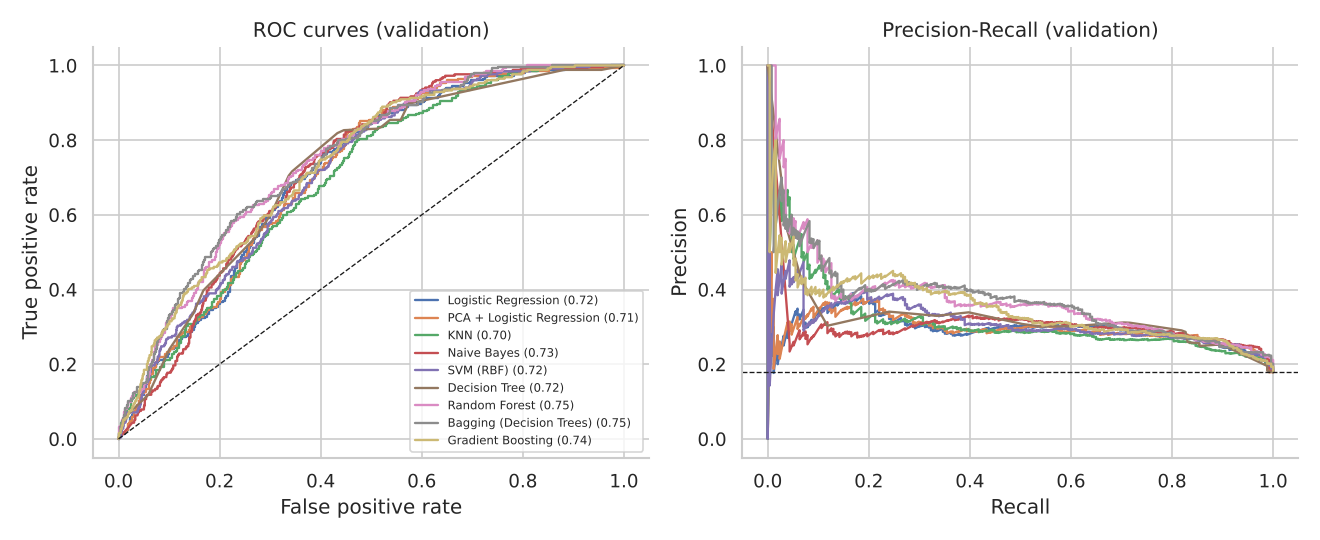

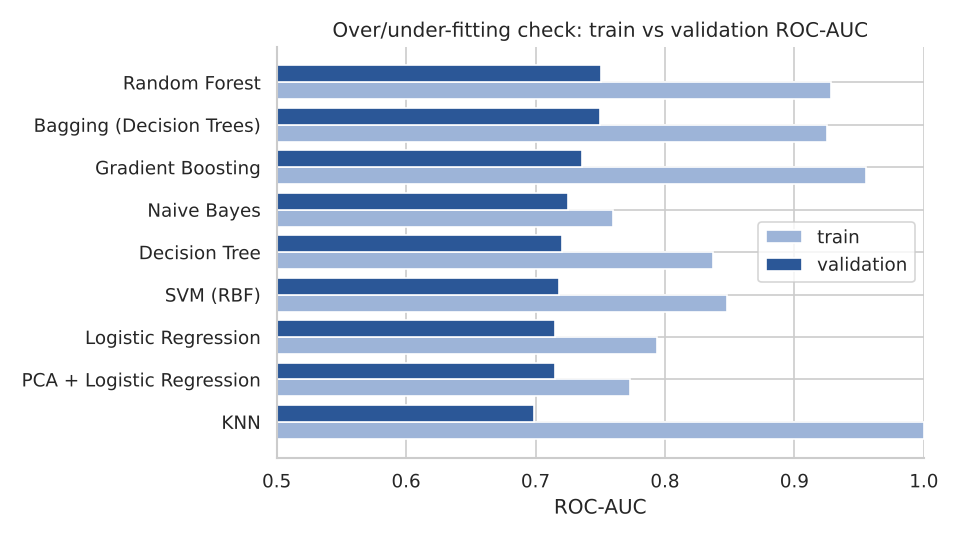

In [7]:
from IPython.display import Image, display
display(Image(FIG / "10_roc_pr_validation.png")); display(Image(FIG / "12_train_vs_val_auc.png"))

**Over/under-fitting (read the train vs validation chart).**
* **KNN** reaches train ROC-AUC 1.00 against 0.70 on validation: distance weighting makes every training point its own nearest neighbour, so it memorises. That is clear over-fitting.
* **Gradient Boosting** (0.96 → 0.74) also over-fits: CV chose unlimited tree depth.
* **Logistic Regression, PCA + LR and Naive Bayes** show small gaps (≈ 0.04-0.08) and low training scores: they are *high-bias* models that under-fit the non-linear signal.
* **Random Forest** (0.93 → 0.75) and **Bagging** (0.93 → 0.75) are the two best models and are essentially tied. Both average many trees, which reduces variance. Random Forest also draws a random subset of features at every split, which de-correlates the trees. By our pre-defined rule (highest validation ROC-AUC) **Random Forest is selected** (0.751 vs 0.750). It still over-fits somewhat; `min_samples_leaf=25` and `max_depth=16` limit this.

Validation is also harder than training because of the **2022-24 inflation shock** (spike rate 18 % vs 15 %).
## Probability calibration
`class_weight="balanced_subsample"` helps the forest notice the rare spikes, but it **inflates the predicted probabilities**: on validation
the raw forest predicts a 44 % average spike chance when the real rate is 18 %. An app that says "59 % chance" when the truth is closer to 20 %
would mislead users. We therefore wrap the selected model in `CalibratedClassifierCV(method="sigmoid")` (Platt scaling) with a 5-fold
`TimeSeriesSplit`. This is decided and checked on **validation** data, and the F1-optimal decision threshold is chosen on the calibrated validation probabilities.
## Final evaluation on the held-out test set (reported once)

final model: Random Forest | decision threshold: 0.221


,model,roc_auc,pr_auc,f1,precision,recall
0,"Random Forest, calibrated (final)",0.829,0.414,0.481,0.377,0.665
1,Baseline: persistence rule,0.614,0.193,0.327,0.330,0.325
2,Baseline: class prior,0.500,0.128,0.000,0.000,0.000


              precision    recall  f1-score   support

    no spike       0.94      0.84      0.89      1304
       spike       0.38      0.66      0.48       191

    accuracy                           0.82      1495
   macro avg       0.66      0.75      0.68      1495
weighted avg       0.87      0.82      0.84      1495



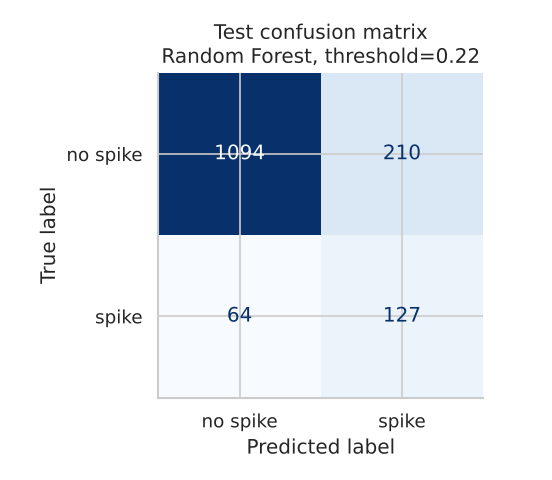

calibration (validation): {'method': 'sigmoid (Platt scaling), CalibratedClassifierCV with 5-fold TimeSeriesSplit', 'val_brier_raw': 0.2045, 'val_brier_calibrated': 0.1318, 'val_mean_prob_raw': 0.4403, 'val_mean_prob_calibrated': 0.1831, 'val_actual_spike_rate': 0.178}


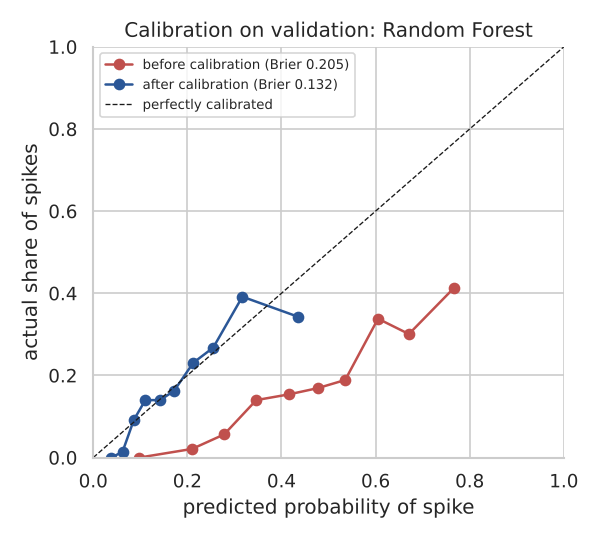

In [8]:
import json
meta = json.loads((C.MODELS_DIR / "metadata.json").read_text())
print("final model:", meta["classifier"], "| decision threshold:", round(meta["decision_threshold"], 3))
display(pd.read_csv(R / "classification_test.csv").round(3))
print((R / "classification_report_test.txt").read_text())
display(Image(FIG / "11_confusion_matrix_test.png"))
print("calibration (validation):", meta["calibration"])
display(Image(FIG / "16_calibration_validation.png"))

## Error analysis

,commodity,rows,spike_rate,roc_auc,f1
1,Eggs,115.0,0.313,0.570,0.493
0,Beans(mash),115.0,0.061,0.571,0.267
12,Wheat flour,115.0,0.200,0.596,0.280
9,Rice (coarse),115.0,0.043,0.607,0.000
8,"Rice (basmati, broken)",115.0,0.043,0.609,0.250
5,Milk,115.0,0.026,0.619,0.000
2,Ghee (artificial),115.0,0.043,0.725,0.000
11,Wheat,115.0,0.296,0.739,0.579
7,Poultry,115.0,0.443,0.741,0.635
10,Sugar,115.0,0.122,0.772,0.440


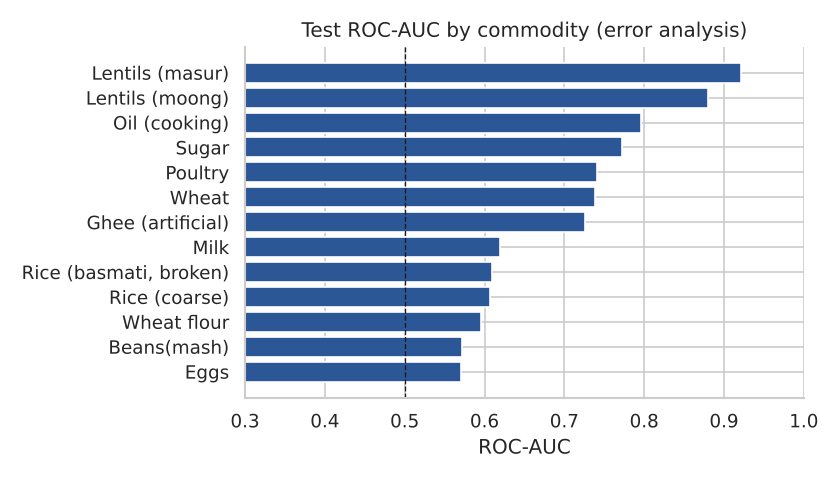

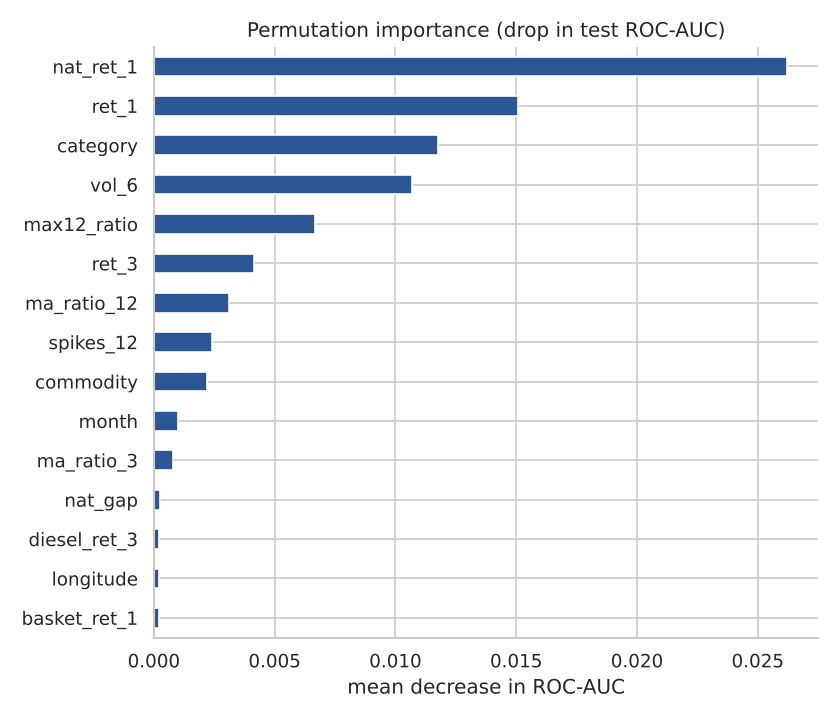

In [9]:
display(pd.read_csv(R / "test_by_commodity.csv").round(3).sort_values("roc_auc"))
display(Image(FIG / "14_test_auc_by_commodity.png")); display(Image(FIG / "13_permutation_importance.png"))

## Companion regression: expected next-month % change (MAE / RMSE / R²)

,model,train_mae,val_mae,val_rmse,val_r2
0,Baseline (train mean),0.0392,0.0448,0.0688,-0.0005
1,Linear Regression,0.0378,0.0483,0.0698,-0.0301
2,Ridge Regression,0.0378,0.0472,0.0686,0.0039
3,Random Forest Regressor,0.0312,0.0429,0.0664,0.0685
4,Gradient Boosting Regressor,0.0312,0.0420,0.0670,0.0525


,model,mae,rmse,r2
0,Gradient Boosting Regressor (final),0.0346,0.0641,0.0542
1,Baseline: train mean,0.0380,0.0661,-0.0039
2,Baseline: no change (0%),0.0356,0.0662,-0.0068


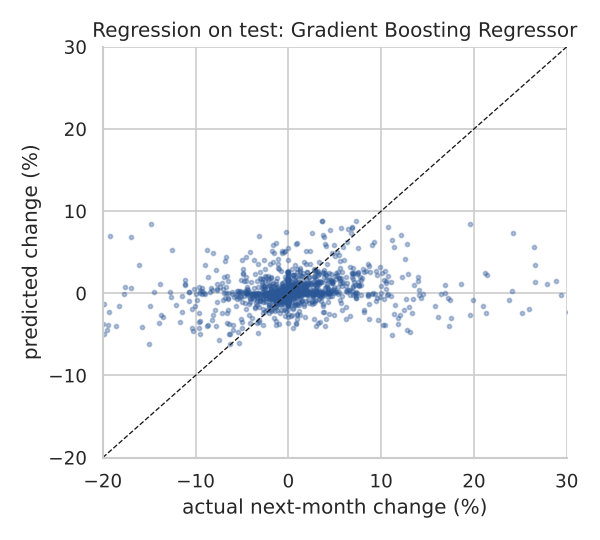

In [10]:
display(pd.read_csv(R / "regression_comparison_validation.csv").drop(columns="best_params").round(4))
display(pd.read_csv(R / "regression_test.csv").round(4)); display(Image(FIG / "15_regression_test_scatter.png"))

Monthly price changes are close to a random walk, so R² is low and the regression only slightly beats "no change". This is the
main argument for framing the problem as **classification** (is a spike coming?), where the models clearly beat the baselines.
## Saved artefacts

In [11]:
import joblib
clf = joblib.load(C.MODELS_DIR / "spike_classifier.joblib")
latest = F.build_features(*F.load_raw()); latest = latest[latest.date == latest.date.max()]
latest.assign(p_spike=clf.predict_proba(latest[M.FEATURES])[:, 1].round(3))[["date", "market", "commodity", "price", "p_spike"]] \
      .sort_values("p_spike", ascending=False).head(10)

,date,market,commodity,price,p_spike
11919,2026-10-15,Multan,Eggs,253.0,0.516
11912,2026-10-15,Lahore,Poultry,363.0,0.442
11938,2026-10-15,Peshawar,Poultry,406.0,0.429
11906,2026-10-15,Lahore,Eggs,259.0,0.427
11925,2026-10-15,Multan,Poultry,393.0,0.408
11893,2026-10-15,Karachi,Eggs,270.0,0.397
11932,2026-10-15,Peshawar,Eggs,276.0,0.382
11951,2026-10-15,Quetta,Poultry,435.0,0.372
11945,2026-10-15,Quetta,Eggs,255.0,0.371
11899,2026-10-15,Karachi,Poultry,438.0,0.322
